# Práctica 3. Detección y reconocimiento de formas

---

**Autores:**
- Alba Ramos Quintana
- Néstor Jesús Henríquez Medina

**Descripción:** Resolución de las tareas de la Práctica 2, incluyendo el conteo de píxeles activos por filas en Canny, la comparativa entre el detector de bordes Canny y Sobel umbralizado, un demostrador interactivo con una pelota virtual que rebota al contacto con la mano y una propuesta extra basada en *My little piece of privacy* con efecto de cristal roto.

---

TAREA 1.1: Los ejemplos ilustrativos anteriores permiten saber el número de monedas presentes en la imagen ideal proporcionada. ¿Cómo determinar la cantidad de dinero presente en ella? A partir únicamente de las dimensiones, una sugerencia impicaría en primer término identificar de forma interactiva (por ejemplo haciendo clic en la imagen) una moneda de un valor fijo en la imagen (por ejemplo de 1€) para permitir establecer una relación entre píxeles y milímetros. Tras obtener esa información y las dimensiones en milímetros de las distintas monedas, es factible calcular la cantidad de dinero en la imagen ideal.

In [58]:
%matplotlib qt

import cv2  
import numpy as np
import matplotlib.pyplot as plt
import csv

diametro_monedas = {
    2.00: 25.75,
    1.00: 23.25,
    0.50: 24.35,
    0.20: 22.25,
    0.10: 19.75,
    0.05: 21.25,
    0.02: 18.75,
    0.01: 16.25
}

def clasificar_moneda(diametro_medido, dicccionario):
    """
    Adivina de qué moneda se trata comparando su tamaño medido con las medidas oficiales.

    Calcula la diferencia entre el diámetro que hemos sacado en milímetros y los 
    tamaños reales del diccionario y escoge la opción que más se acerque.
    """
    moneda = None
    min_diferencia = float('inf')

    for valor, diametro in dicccionario.items():
        dif = abs(diametro - diametro_medido)
        if dif < min_diferencia:
            min_diferencia = dif
            moneda = valor
    return moneda

img = cv2.imread('Monedas.jpg') 
#img = cv2.imread('monedas2.jpg')
print(img.shape)

img_gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

img_suavizada = cv2.GaussianBlur(img_gris, (5, 5), 0)
#img_suavizada = cv2.medianBlur(img_gris, 5)

th,img_th = cv2.threshold(img_suavizada,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
print('Umbral Otsu ', th)

contornos, _ = cv2.findContours(
    img_th, 
    cv2.RETR_EXTERNAL , 
    cv2.CHAIN_APPROX_SIMPLE
    )

print("Hay un total de", len(contornos), "contonos detectados")


# Fuente: https://hetpro-store.com/TUTORIALES/opencv-findcontours/?srsltid=AU7gw4Vh8qvHAzdz3LKVhhBp38z6-qQP5ekuIxHiYYR8xJRL_PztFQNX
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
cv2.drawContours(img_rgb, contornos, -1, (0,0,255), 3)

plt.plot()
plt.axis("off")
plt.imshow(img_rgb) 

# Fuente: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.ginput.html
# Fuente: búsqueda en Google - "ginput() en ipynb"
# pip install PyQt5
pts = plt.ginput(1)

if len(pts) > 0:
    clic_x, clic_y = pts[0]
    print(f"Coordenada seleccionada: X= {clic_x:.2f}, Y= {clic_y:.2f}")

    contorno_ref = None
    for contorno in contornos:
        # Fuente: búsqueda en Google - "Averiguar punto dentro de un contorno con findContours()"
        ref = cv2.pointPolygonTest(contorno, (clic_x, clic_y), False)
        #print(ref)
        if ref >= 0:
            contorno_ref = contorno
            print("Esto es una moneda")
            break

    # Fuente: https://docs.opencv.org/4.13.0/dd/d49/tutorial_py_contour_features.html
    if contorno_ref is not None:
        _, radio_ref = cv2.minEnclosingCircle(contorno_ref)
        diametro_ref = radio_ref*2
        escala = diametro_monedas[1.00] / diametro_ref
        #print(escala)

        cv2.drawContours(img_rgb, [contorno_ref], -1, (0,255,0), 5)
        plt.imshow(img_rgb)
        plt.draw()

        total = 0
        diametro_min_px = 15/escala # min 15 mm
        for contorno in contornos:
            centro, radio = cv2.minEnclosingCircle(contorno)
            diametro_px = radio * 2
            
            # Si es muy pequeño, pasamos al siguiente contorno
            if diametro_px < diametro_min_px:
                continue
                
            diametro_mm = diametro_px * escala
            valor_moneda = clasificar_moneda(diametro_mm, diametro_monedas)
            
            total += valor_moneda
            
            texto = f"{valor_moneda}€"
            x, y = int(centro[0]), int(centro[1])
            cv2.putText(img_rgb, texto, (x - 20, y + 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 255), 2, cv2.LINE_AA)
        
        total_text = f"TOTAL = {total:.2f}€"
        tam_text, _ = cv2.getTextSize(total_text, cv2.FONT_HERSHEY_SIMPLEX, 1.2, 2)

        cv2.putText(img_rgb, total_text, (int((img.shape[1] - tam_text[0]) / 2), img.shape[0]), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (0, 0, 0), 2, cv2.LINE_AA)

        print("\n==============")
        print(total_text)
        print("==============")


        plt.imshow(img_rgb)
        plt.draw()


(938, 473, 3)
Umbral Otsu  208.0
Hay un total de 10 contonos detectados
Coordenada seleccionada: X= 119.26, Y= 358.36
Esto es una moneda

TOTAL = 3.88€


TAREA 1.2: Una vez resuelto el reto con la imagen ideal proporcionada, diseña un demostrador en vivo que a partir de la entrada de vídeo de la cámara, determine el dinero presente en la escena. Si bien 
no hay restricciones sobre utilizar medidas geométricas o de color, o cualquier clasificador, no deben hacer uso de modelos de aprendizaje profundo. ¿Funciona correctamente? ¿Se observan problemas?
Posibles extras serían la presencia de objetos que no son monedas y/o haya solape entre las monedas.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo

Nota: Para establecer la correspondencia entre píxeles y milímetros, comentar que la moneda de un euro tiene un diámetro de 23.25 mm. la de 50 céntimos de 24.35, la de 20 céntimos de 22.25, etc. 

In [ ]:
import cv2
import numpy as np

diametro_monedas = {
    2.00: 25.75,
    1.00: 23.25,
    0.50: 24.25,
    0.20: 22.25,
    0.10: 19.75,
    0.05: 21.25,
    0.02: 18.75,
    0.01: 16.25
}

def clasificar_moneda(diametro_medido, diccionario):
    """Adivina de qué moneda se trata comparando su tamaño medido con las medidas oficiales."""
    moneda = None
    min_diferencia = float('inf')
    for valor, diametro in diccionario.items():
        dif = abs(diametro - diametro_medido)
        if dif < min_diferencia:
            min_diferencia = dif
            moneda = valor
    return moneda

escala = None
punto_clic = None
invertir_mascara = False

# Fuente: https://www.geeksforgeeks.org/python/click-response-on-video-output-using-events-in-opencv-python/
def detectar_clic(evento, x, y, flags, param):
    """Guarda las coordenadas al hacer clic izquierdo."""
    global punto_clic
    if evento == cv2.EVENT_LBUTTONDOWN:
        punto_clic = (x, y)

vid = cv2.VideoCapture(1)

cv2.namedWindow('Cam')
cv2.setMouseCallback('Cam', detectar_clic)

# Fuente: https://www.geeksforgeeks.org/python/clahe-histogram-eqalization-opencv/
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))

while True:
    ret, frame = vid.read()

    if ret:
        gris = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
        
        gris_clahe = clahe.apply(gris)
        
        # Fuente: https://www.geeksforgeeks.org/python/python-bilateral-filtering/
        gris_suavizado = cv2.bilateralFilter(gris_clahe, d=11, sigmaColor=75, sigmaSpace=75)
        
        if invertir_mascara:
            modo_umbral = cv2.THRESH_BINARY_INV
        else:
            modo_umbral = cv2.THRESH_BINARY
            
        img_th = cv2.adaptiveThreshold(gris_suavizado, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, 
                                       modo_umbral, 99, 25)

        kernel = np.ones((5,5), np.uint8)
        # Fuente: https://www.luisllamas.es/opencv-operaciones-morfologicas-erosion-dilatacion/
        img_th = cv2.morphologyEx(img_th, cv2.MORPH_CLOSE, kernel, iterations=2)
        img_th = cv2.morphologyEx(img_th, cv2.MORPH_OPEN, kernel, iterations=1)

        contornos, _ = cv2.findContours(img_th, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

        # Calibración al hacer clic
        if punto_clic is not None and escala is None:
            for contorno in contornos:
                if cv2.pointPolygonTest(contorno, punto_clic, False) >= 0:
                    _, radio_ref = cv2.minEnclosingCircle(contorno)
                    if radio_ref > 0:
                        diametro_ref = radio_ref * 2
                        escala = diametro_monedas[1.00] / diametro_ref
                        print(f"Calibrada escala: {escala:.4f}")
            punto_clic = None

        # Detección y Suma
        if escala is None:
            cv2.putText(frame, "Haz clic en la de 1€ (Pulsa 'R' para cambiar fondo)", (20, 40), 
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 0, 0), 2)
        else:
            total = 0.0
            for c in contornos:
                area = cv2.contourArea(c)
                if area < 150: # Ignorar manchas pequeñas
                    continue
                    
                perimetro = cv2.arcLength(c, True)
                if perimetro == 0:
                    continue
                
                compacidad = (perimetro ** 2) / area
                
                # Filtrar solo objetos circulares
                if 12.0 < compacidad < 25.0:
                    centro, radio = cv2.minEnclosingCircle(c)
                    diametro_px = radio * 2
                    diametro_mm = diametro_px * escala
                    
                    if diametro_mm > 15.0:
                        valor = clasificar_moneda(diametro_mm, diametro_monedas)
                        total += valor
                        
                        cv2.circle(frame, (int(centro[0]), int(centro[1])), int(radio), (0, 255, 0), 2)
                        x_txt, y_txt = int(centro[0]), int(centro[1])
                        cv2.putText(frame, f"{valor}E", (x_txt - 20, y_txt + 5), 
                                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)
            
            texto_total = f"TOTAL = {total:.2f} €"
            cv2.putText(frame, texto_total, (20, frame.shape[0] - 30), 
                        cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 255, 255), 2)

        cv2.imshow('Cam', frame)
        cv2.imshow('Mascara', img_th)

    tecla = cv2.waitKey(20) & 0xFF
    if tecla == 27: 
        break
    elif tecla == ord('r') or tecla == ord('R'): 
        invertir_mascara = not invertir_mascara
        escala = None 
        print("Máscara invertida")

vid.release()
cv2.destroyAllWindows()

Calibrada escala: 0.0291
Máscara invertida
Máscara invertida


La segunda tarea plantea la clasificación de microplásticos en una imagen real. Dado que el mundo real es muy variado, las imágenes no siempre se capturan con unas condiciones de iluminación tan buenas o controladas. Ejemplo con aplicación de variantes de umbralizados ofrecidas por OpenCV sobre una imagen de muestras de microplásticos.

Umbral escogido  197.0


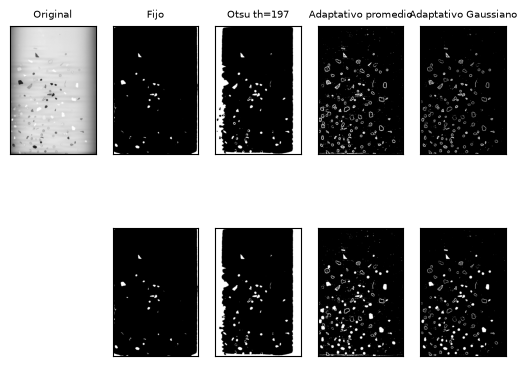

In [ ]:
#Carga imagen directamente en grises
imgorig = cv2.imread('MPs_test.jpg', cv2.IMREAD_GRAYSCALE) 

img = cv2.GaussianBlur(imgorig,(5,5),0)

#Umbralizados
ret,imth = cv2.threshold(img,150,255,cv2.THRESH_BINARY_INV)
thotsu,imth2 = cv2.threshold(img,0,255,cv2.THRESH_BINARY_INV+cv2.THRESH_OTSU)
print('Umbral escogido ', thotsu)
imth3 = cv2.adaptiveThreshold(img,255,cv2.ADAPTIVE_THRESH_MEAN_C,\
            cv2.THRESH_BINARY,11,2)
imth4 = cv2.adaptiveThreshold(img,255,cv2.ADAPTIVE_THRESH_GAUSSIAN_C,\
            cv2.THRESH_BINARY,11,2)
 
titles = ['Original', 'Fijo','Otsu th='+str(int(thotsu)),
            'Adaptativo promedio', 'Adaptativo Gaussiano']
images = [img, imth, imth2, 255 - imth3, 255 - imth4]
 
for i in range(5):
    plt.subplot(2,5,i+1),plt.imshow(images[i],'gray')
    plt.title(titles[i], fontsize=7)
    plt.xticks([]),plt.yticks([])

    #Obtiene únicamente los contornos externos
    if i>0:
        res,imth = cv2.threshold(images[i],120,255,cv2.THRESH_BINARY)
        contornos, hierarchy= cv2.findContours(imth, 
        cv2.RETR_EXTERNAL , 
        cv2.CHAIN_APPROX_SIMPLE)  
        img_cont = np.zeros(img.shape)
        cv2.drawContours(img_cont, contornos, -1, (255,255,255), -1)  
        plt.subplot(2,5,i+6),plt.imshow(img_cont,'gray')
        plt.xticks([]),plt.yticks([])
plt.show()

Para esta imagen de muestras de microplásticos tenemos una anotación (que puede contener errores) de la tipología de las partículas. Esta será la imagen de test en los experimentos posteriores, no puedes hacer uso de esta imagen para entrenar tu clasificador, solo par evaluarlo

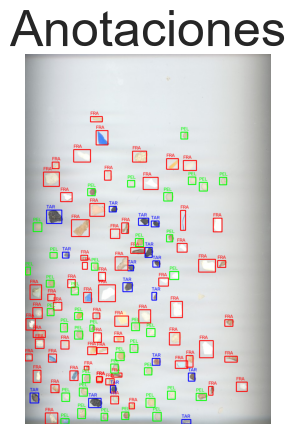

In [44]:
# Imagen y anotaciones
imagen = "MPs_test.jpg"          # Imagen original
csv_file = "MPs_test_bbs.csv"  # CSV con coordenadas y tipología

# Colores de cada clase
colores = {
    "FRA": (0, 0, 255),   # Rojo 
    "PEL": (0, 255, 0),   # Verde
    "TAR": (255, 0, 0)    # Azul
}

# Imagen
img = cv2.imread(imagen)

# Cara csv y dibujar rectángulos
with open(csv_file, newline="") as file:
    reader = csv.DictReader(file)
    for row in reader:
        etiqueta = row["label"]
        x_min, y_min, x_max, y_max = map(int, [row["x_min"], row["y_min"], row["x_max"], row["y_max"]])
        
        # Color según etiqueta
        color = colores.get(etiqueta, (0, 0, 0))  # negro por defecto si no encuentra
        
        # Dibujar rectángulo
        cv2.rectangle(img, (x_min, y_min), (x_max, y_max), color, 2)
        
        # Etiqueta 
        cv2.putText(img, etiqueta, (x_min, y_min - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1)

# Visualiza resultado
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Anotaciones")
plt.axis('off')
plt.show()


## Muestras de entrenamiento

Text(0.5, 1.0, 'Alquitrán')

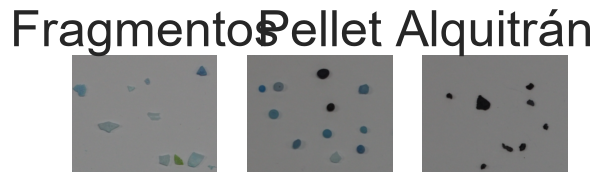

In [12]:
#Cargamos tres subimágenes, por simplicidad, de cada uno de los tres tipos considerados (reiterar que el alquitrán no es microplástico)
imgF = cv2.imread('FRA.png') 
imgP = cv2.imread('PEL.png') 
imgT = cv2.imread('TAR.png') 

#Mostramos
plt.subplot(131)
plt.axis("off")
plt.imshow(imgF) 
plt.title('Fragmentos')
plt.subplot(132)
plt.axis("off")
plt.imshow(imgP) 
plt.title('Pellet')
plt.subplot(133)
plt.axis("off")
plt.imshow(imgT) 
plt.title('Alquitrán')

El objetivo de la siguiente tarea, descrita más abajo, es desarrollar tu propio clasificador basado únicamente en heurísticas basadas en características geométricas y/o de apariencia, a partir de las imágenes completas de las partículas de cada tipo, debiendo mostrar la bondad del clasificador haciendo uso de métricas para ello sobre las anotaciones de la imagen de test *MPs_test.png*. La siguiente celda obtiene varias métricas para un conjunto de datos imaginario (y con etiquetas aleatorias). Si bien las trataremos con más detalle en teoría, muestro un repertorio de ellas, dando más peso a la matriz de confusión. La ejecución de la celda requiere instalar el paquete scikit-learn.

¿Qué es una matriz de confusión?
Se utiliza para mostrar el comportamiento de un clasificador para las distintas clases conocidas, se relacionan las etiquetas de las muestras anotadas frente a las predichas por el clasificador. Se busca una matriz diagonal, pero la perfección es infrecuente.

El siguiente ejemplo, muestra el modo de obtener la matriz de confusión para un hipotético problema con cuatro clases, y valores de anotación (variable y) y predicción (variable y_pred) obtenidos de forma aleatoria.

Anotaciones  [3, 0, 3, 1, 3, 2, 3, 3, 0, 2, 2, 2, 1, 2, 0, 0, 0, 2, 2, 2, 3, 3, 1, 2, 1, 3, 2, 0, 1, 0, 2, 3, 3, 3, 2, 2, 2, 1, 1, 1, 0, 3, 3, 3, 2, 1, 2, 3, 0, 3, 0, 3, 1, 3, 1, 1, 2, 0, 1, 1, 3, 0, 2, 3, 1, 2, 3, 3, 0, 2, 1, 2, 1, 0, 1, 0, 3, 2, 3, 2, 2, 3, 1, 0, 1, 0, 2, 1, 1, 1, 0, 2, 3, 2, 3, 1, 3, 0, 3, 1]
Predicciones  [1, 0, 0, 2, 2, 3, 3, 1, 3, 1, 0, 1, 1, 0, 0, 1, 0, 2, 0, 3, 3, 2, 0, 1, 3, 0, 3, 3, 2, 0, 0, 1, 1, 2, 3, 2, 2, 0, 3, 3, 2, 1, 2, 0, 3, 2, 3, 1, 0, 2, 3, 2, 1, 2, 2, 3, 0, 3, 1, 1, 0, 1, 3, 0, 3, 0, 0, 0, 1, 2, 3, 0, 3, 0, 1, 1, 3, 0, 1, 3, 2, 3, 1, 0, 2, 2, 0, 3, 1, 1, 0, 2, 3, 1, 1, 3, 2, 0, 2, 3]
¿Cómo de bien encajan anotación y predicción?
Accuracy (TP/(n))= 0.28
Precision (TP/(TP+FP)) = 0.274006734006734
Recall (TP/(TP+FN)) = 0.28
F1 Score (2*(precision*recall)/(precision+recall)) = 0.27388864241348715


Text(38.236490885416664, 0.5, 'Real/Anotado')

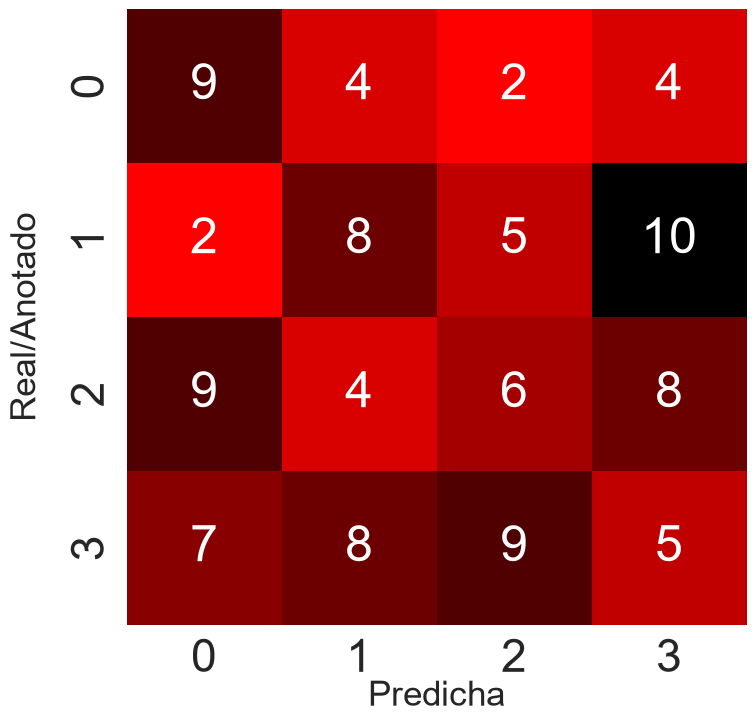

In [45]:

import random
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# Numero de muestras
n = 100  
nclases = 4

# A falta de clasificador y conjunto de datos, creamos anotaciones y predicciones de forma aleatoria
# Vector aleatorio con etiquetas anotadas
y = [random.randint(0, nclases - 1) for _ in range(n)]
print('Anotaciones ' , y)

# Vector aleatorio con etiquetas predichas por un supuesto clasificador
y_pred = [random.randint(0, nclases - 1) for _ in range(n)]
print('Predicciones ' , y_pred)

print('¿Cómo de bien encajan anotación y predicción?')

#Cálculo de métricas
accuracy = accuracy_score(y, y_pred)
#Para más de una clase se define la forma de promediar
precision = precision_score(y, y_pred,average='weighted')
recall = recall_score(y, y_pred,average='weighted')
f1score = f1_score(y, y_pred,average='weighted')

print(f"Accuracy (TP/(n))= {accuracy}")
print(f"Precision (TP/(TP+FP)) = {precision}")
print(f"Recall (TP/(TP+FN)) = {recall}")
print(f"F1 Score (2*(precision*recall)/(precision+recall)) = {f1score}")


conf_matrix = confusion_matrix(y, y_pred)
plt.figure(figsize=(8,8))
sns.set(font_scale = 1.75)#tamaños tipografía
sns.set(font_scale = 3.0)

ax = sns.heatmap(
        conf_matrix, # confusion matrix 2D array 
        annot=True, # Muestra números en las celdas
        fmt='d', # valores enteros
        cbar=False, # sin barra de colores
        cmap='flag', # mapa de colores
        #vmax=175 # contraste de color
    )

#Etiquetas matriz de confusión
label_font = {'size':'25'}
ax.set_xlabel("Predicha", labelpad=-0.75, fontdict=label_font)
ax.set_ylabel("Real/Anotado", labelpad=20, fontdict=label_font)

TAREA: La tarea consiste en extraer características (geométricas y/o visuales) de las tres imágenes completas de partida, y *aprender* patrones que permitan identificar las partículas en nuevas imágenes. Para ello se proporciona como imagen de test *MPs_test.jpg* y sus correpondientes anotaciones *MPs_test_bbs.csv* con la que deben obtener las métricas para su propuesta de clasificación de microplásticos, además de la matriz de confusión. La matriz de confusión permitirá mostrar para cada clase el número de muestras que se clasifican correctamente de dicha clase, y el número de muestras que se clasifican incorrectamente como perteneciente a una de las otras dos clases. De nuevo, no deben hacer uso de modelos de aprendizaje `profunfop ni poara segmentar,  ni para clasificar.

En el trabajo [SMACC: A System for Microplastics Automatic Counting and Classification](https://doi.org/10.1109/ACCESS.2020.2970498), las características geométricas utilizadas fueron:

- Área en píxeles
- Perímetro en píxeles
- Compacidad (relación entre el cuadrado del perímetro y el área de la partícula)
- Relación del área de la partícula con la del contenedor
- Relación del ancho y el alto del contenedor
- Relación entre los ejes de la elipse ajustada
- Definido el centroide, relación entre las distancias menor y mayor al contorno

Si no se quedan satisfechos con la segmentación obtenida, es el mundo real, también en el README comento técnicas recientes de segmentación, que podrían despertar su curiosidad.

IMPORTANTE: No se admite el uso de modelos de aprendizaje profundo